# 10 · Final Model: Improved Classical NLP

**Purpose:** improve on the notebook 08 model using **classical** NLP only: sentiment-aware preprocessing, richer TF-IDF features and a Naive-Bayes-weighted Logistic Regression. No deep learning or pretrained language models are used.

**Questions answered**
- Which preprocessing, feature and classifier changes help, judged by cross-validation on the training set only?
- How large is the gain on held-out data, per class and overall?
- Is the gain consistent across random splits when hyperparameters are re-tuned inside each split?
- What did fixing the URL/emoticon preprocessing bug change?

**Rules that keep the result honest**
1. Every candidate is compared with **5-fold cross-validation on the training set only**.
2. The best candidate is chosen by cross-validated Macro-F1, and **only then** evaluated once on the held-out test tweets.
3. No label-derived columns, no test-set tuning, and no removal of difficult tweets.

The model selected here is the project's final model; `python -m src.train` retrains and saves it.

> **Labels vs predictions:** the descriptive analysis (notebooks 03–05) uses the sentiment labels supplied with the dataset. The models here *predict* those labels from text, for evaluation and for new tweets. Predictions never replace the supplied labels.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable from any folder inside the repository
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import html
import re
import time

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.container import BarContainer

from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import LinearSVC

from src.config import RANDOM_STATE, SENTIMENT_LABELS
from src.data import load_clean_tweets, split_train_test
from src.evaluation import fit_and_score, per_class_report, repeated_split_evaluation, score_predictions
from src.features import final_tfidf, word_char_tfidf
from src.modeling import (
    FINAL_C, NBLogisticRegression, balanced_logistic_regression, build_final_model, build_word_char_lr, build_word_lr,
)
from src.plotting import PRIMARY_COLOR, SENTIMENT_COLORS, apply_style, save_figure
from src import preprocessing as pp
from src.preprocessing import clean_texts_plus, clean_tweet, clean_tweet_plus

apply_style()

df = load_clean_tweets()
train_df, test_df = split_train_test(df)
X_train, y_train = train_df["text"], train_df["airline_sentiment"]    # raw text: each pipeline cleans it itself
X_test, y_test = test_df["text"], test_df["airline_sentiment"]
print(f"Training tweets: {len(train_df):,} | Test tweets: {len(test_df):,}")

Training tweets: 11,584 | Test tweets: 2,897


### Where the code lives

- `src/preprocessing.py` – `clean_tweet` (notebooks 06–08) and `clean_tweet_plus` (this notebook)
- `src/features.py` – `word_char_tfidf` (notebook 08) and `final_tfidf` (this notebook)
- `src/modeling.py` – `NBLogisticRegression`, `build_word_char_lr` and `build_final_model`
- `tests/` – unit tests for the cleaning rules (URLs, emoticons, emoji, negation, contractions, missing values) and the models

## 1. Improvement 1: Richer Text Preprocessing

`clean_tweet_plus` extends the notebook 06 cleaning with four steps that matter for sentiment:

| Step | Example | Why |
|---|---|---|
| Emoticons → tokens | `:(` → `emo_neg`, `:)` → `emo_pos` | Emoticons carry strong sentiment but are split into meaningless characters by default |
| Emoji kept as separate tokens | `great😍` → `great 😍` | Lets the model learn each emoji |
| Elongations shortened | `sooooo` → `soo` | Merges spelling variants of the same emphasised word |
| **Negation scope marking** | `not happy at all` → `not happy_neg at_neg all_neg` | "happy" after "not" should not count as positive; marking the next three words (until punctuation) separates the two meanings. Contractions with straight or curly apostrophes (`don't`, `don’t`) and apostrophe-less forms (`dont`, `cant`) all count as negations |

**Order matters.** URLs and @mentions are removed *before* emoticons are detected. An earlier version did it the other way round, so the `:/` inside every `http://` link was turned into a false `emo_neg` token and URL fragments (`http`, `t.co`, `/`) leaked into the features. Section 1.1 measures the effect of that fix.

In [2]:
examples = [
    "@united NOT happy :( sooooo late",
    "Thanks @SouthwestAir!!! 😍 best crew",
    "@USAirways I don’t think anyone is answering, still on hold &amp; waiting",
    "@JetBlue great flight http://t.co/abc123",
]
pd.DataFrame({"raw": examples,
              "clean_tweet (notebook 06)": [clean_tweet(t) for t in examples],
              "clean_tweet_plus (this notebook)": [clean_tweet_plus(t) for t in examples]})

,raw,clean_tweet (notebook 06),clean_tweet_plus (this notebook)
0,@united NOT happy :( sooooo late,not happy :( sooooo late,not happy_neg emo_neg soo_neg late
1,Thanks @SouthwestAir!!! 😍 best crew,thanks !!! 😍 best crew,thanks ! ! ! 😍 best crew
2,"@USAirways I don’t think anyone is answering, ...","i don't think anyone is answering, still on ho...",i don't think_neg anyone_neg is_neg answering ...
3,@JetBlue great flight http://t.co/abc123,great flight,great flight


### 1.1 Effect of the URL/Emoticon Bug Fix

`legacy_clean_tweet_plus` below reproduces the earlier, buggy order (emoticons first, URLs second) only for this comparison. Both versions are plugged into the final pipeline and compared with 5-fold cross-validation on the training set.

In [3]:
LEGACY_EMOTICONS = {r"[:;=]-?[)\]dp]": " emo_pos ", r"[:;=]-?[(\[/\\|]": " emo_neg ", r"<3": " emo_pos "}


def legacy_clean_tweet_plus(text):
    """Same steps as clean_tweet_plus, but with the earlier emoticon handling:
    emoticons were replaced BEFORE URLs were removed, with no word-boundary checks."""
    text = html.unescape(str(text)).translate(pp.APOSTROPHES)
    for pattern, token in LEGACY_EMOTICONS.items():
        text = re.sub(pattern, token, text, flags=re.IGNORECASE)
    text = pp.MENTION_PATTERN.sub(" ", pp.URL_PATTERN.sub(" ", text))
    text = pp.EMOJI_PATTERN.sub(r" \1 ", pp.EMOJI_JOINERS.sub("", text)).lower()
    text = pp.ELONGATION_PATTERN.sub(r"\1\1", text)
    return pp.mark_negations(pp.WHITESPACE_PATTERN.sub(" ", text).strip())


def legacy_clean_texts(texts):
    return [legacy_clean_tweet_plus(t) for t in texts]


affected = X_train.str.contains("http", case=False)
print(f"Training tweets containing a URL: {affected.sum():,} ({affected.mean():.1%})")
print("Legacy:", legacy_clean_tweet_plus("@JetBlue great flight http://t.co/abc123"))
print("Fixed: ", clean_tweet_plus("@JetBlue great flight http://t.co/abc123"))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
bug_rows = []
for name, cleaner in [("Legacy emoticon handling (bug)", legacy_clean_texts), ("Fixed order", clean_texts_plus)]:
    pipeline = Pipeline([("clean", FunctionTransformer(cleaner)), ("features", final_tfidf()),
                         ("model", NBLogisticRegression(C=FINAL_C))])
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=["f1_macro", "accuracy"], n_jobs=-1)
    bug_rows.append({"cleaning": name, "cv_macro_f1": scores["test_f1_macro"].mean(),
                     "cv_macro_f1_std": scores["test_f1_macro"].std(), "cv_accuracy": scores["test_accuracy"].mean()})
pd.DataFrame(bug_rows).set_index("cleaning").round(4)

Training tweets containing a URL: 940 (8.1%)
Legacy: great flight emo_neg / t . co / abc123
Fixed:  great flight


,cv_macro_f1,cv_macro_f1_std,cv_accuracy
cleaning,,,
Legacy emoticon handling (bug),0.7708,0.0079,0.8170
Fixed order,0.7706,0.0094,0.8172


**Interpretation:** the fix changes cross-validated scores by less than 0.001 macro-F1, far inside the fold-to-fold standard deviation (≈0.009). The bug was a correctness problem (false `emo_neg` tokens and URL fragments in about 8% of tweets), not a source of the reported accuracy; the corrected cleaning is kept because it is right, not because it scores higher.

## 2. Improvement 2: Richer TF-IDF Features

Compared with notebook 08 (`src.features.final_tfidf`):
- **Punctuation tokens:** the default word tokenizer drops `?` and `!`. Neutral tweets are often questions, so `?` is informative.
- **No vocabulary caps:** Notebook 08 limited the vocabulary to 40,000 word and 50,000 character features. With ~11,600 training tweets the full vocabulary fits comfortably.
- **Wider character n-grams:** 2–6 characters instead of 3–5.

## 3. Improvement 3: Naive-Bayes-Weighted Logistic Regression (NB-LR)

NB-LR follows the "NBSVM" idea of Wang & Manning (2012), a classic, strong baseline for sentiment classification:

1. For each class (one-vs-rest), compute every feature's **Naive Bayes log-count ratio**, r = log( p(feature | class) / p(feature | other classes) ).
2. Multiply the features by r, so terms typical of the class ("thanks" for Positive, "delayed" for Negative) are boosted.
3. Train a balanced Logistic Regression on the re-weighted features.

**How this implementation differs from the original NBSVM** (`src.modeling.NBLogisticRegression`):

| | Original NBSVM | This project |
|---|---|---|
| Features used for r | binarised counts | TF-IDF weights (summed per class) |
| Classifier | linear SVM | class-balanced Logistic Regression, so it outputs probabilities |
| Weight interpolation (β) | yes | none |
| Multi-class | binary task | one-vs-rest, probabilities normalised to sum to 1 |

The ratios are computed inside `fit`, so within a pipeline they are learned from training folds only.

## 4. Cross-Validated Comparison (training set only)

Each step is added one at a time so its contribution is visible. Scores are the mean ± standard deviation of 5 folds.

In [4]:
candidates = {
    "A. Notebook 08 model (reference)": build_word_char_lr(),
    "B. A + clean_tweet_plus": Pipeline([
        ("clean", FunctionTransformer(clean_texts_plus)), ("features", word_char_tfidf()),
        ("model", balanced_logistic_regression(C=2, max_iter=3000))]),
    "C. B + punctuation tokens, no caps, char 2-6": Pipeline([
        ("clean", FunctionTransformer(clean_texts_plus)), ("features", final_tfidf()),
        ("model", balanced_logistic_regression(C=1, max_iter=3000))]),
    "D. C features + Linear SVM (C=0.1)": Pipeline([
        ("clean", FunctionTransformer(clean_texts_plus)), ("features", final_tfidf()),
        ("model", LinearSVC(C=0.1, class_weight="balanced", random_state=RANDOM_STATE))]),
}
for C in [4, 8, 16]:
    candidates[f"E. C features + NB-LR (C={C})"] = build_final_model(C=C)

rows = []
for name, pipeline in candidates.items():
    start = time.time()
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=["f1_macro", "accuracy"], n_jobs=-1)
    rows.append({"candidate": name,
                 "cv_macro_f1": scores["test_f1_macro"].mean(), "cv_macro_f1_std": scores["test_f1_macro"].std(),
                 "cv_accuracy": scores["test_accuracy"].mean(), "seconds": round(time.time() - start)})

cv_results = pd.DataFrame(rows).set_index("candidate")
cv_results.round(4)

,cv_macro_f1,cv_macro_f1_std,cv_accuracy,seconds
candidate,,,,
A. Notebook 08 model (reference),0.7578,0.0060,0.8079,23
B. A + clean_tweet_plus,0.7616,0.0063,0.8098,14
"C. B + punctuation tokens, no caps, char 2-6",0.7651,0.0063,0.8097,19
D. C features + Linear SVM (C=0.1),0.7695,0.0044,0.8217,9
E. C features + NB-LR (C=4),0.7706,0.0094,0.8172,16
E. C features + NB-LR (C=8),0.7703,0.0062,0.8191,17
E. C features + NB-LR (C=16),0.7664,0.0053,0.8180,19


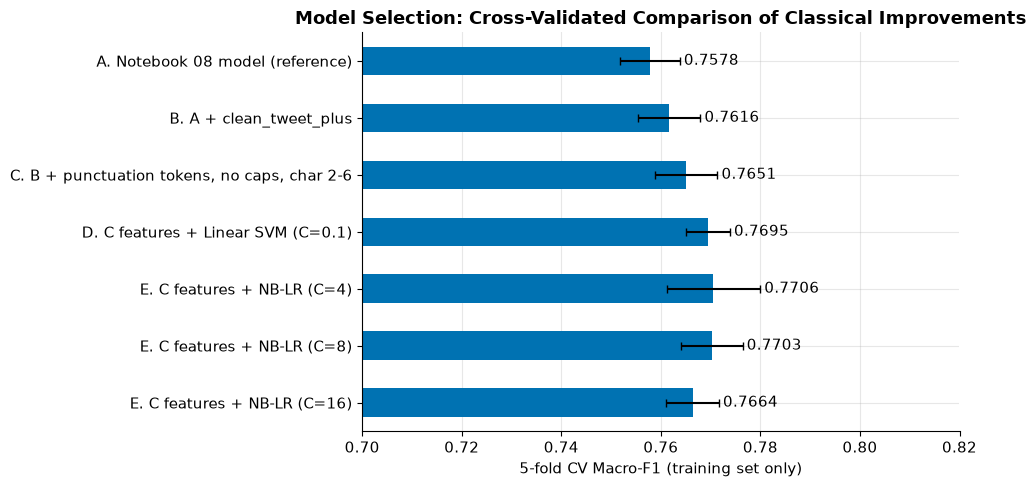

Selected by CV Macro-F1: E. C features + NB-LR (C=4)


In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
cv_results["cv_macro_f1"].plot(kind="barh", xerr=cv_results["cv_macro_f1_std"], color=PRIMARY_COLOR, capsize=3, ax=ax)
ax.set_xlim(0.70, 0.82)
ax.invert_yaxis()
ax.set_xlabel("5-fold CV Macro-F1 (training set only)")
ax.set_ylabel("")
ax.set_title("Model Selection: Cross-Validated Comparison of Classical Improvements")
bars = [c for c in ax.containers if isinstance(c, BarContainer)][0]
ax.bar_label(bars, fmt="%.4f", padding=3)
plt.tight_layout()
save_figure("model_selection_cv.png")
plt.show()

best_candidate = cv_results["cv_macro_f1"].idxmax()
print(f"Selected by CV Macro-F1: {best_candidate}")
# src.train uses build_final_model(C=FINAL_C); fail loudly if the selection no longer matches it
assert best_candidate == f"E. C features + NB-LR (C={FINAL_C})", "Update FINAL_C in src/modeling.py"

**Interpretation:** cross-validated Macro-F1 rises from A to C as preprocessing (+0.004) and features (+0.004) are improved, and again with a stronger classifier (C → D/E, about +0.005). NB-LR (C=4) is selected by the pre-declared rule (best CV Macro-F1), but its lead over the Linear SVM (0.7706 vs 0.7695) and over NB-LR with C=8 is well within one standard deviation, and the SVM has slightly higher CV accuracy (0.822 vs 0.817). The ranking among D and E is therefore not certain; NB-LR is also preferred because it outputs probabilities.

## 5. Final Evaluation on the Held-Out Test Set

The selected model is refitted on the full training set and evaluated **once** on the test set. For context, the reference models are scored on the same test tweets.

In [6]:
final_model = candidates[best_candidate].fit(X_train, y_train)
final_predictions = final_model.predict(X_test)

reference_nb08 = build_word_char_lr().fit(X_train, y_train)
progression = pd.DataFrame([
    fit_and_score("Dummy (always Negative)", DummyClassifier(strategy="most_frequent"), X_train, y_train, X_test, y_test),
    fit_and_score("Word TF-IDF + LR (notebook 06)", build_word_lr(), X_train, y_train, X_test, y_test),
    {"model": "Word + char TF-IDF + LR (notebook 08)", **score_predictions(y_test, reference_nb08.predict(X_test))},
    {"model": "Final: NB-LR (notebook 10)", **score_predictions(y_test, final_predictions)},
]).set_index("model")
display(progression.round(4))

gain = progression.iloc[-1] - progression.loc["Word + char TF-IDF + LR (notebook 08)"]
print(f"Gain over notebook 08: accuracy {gain['accuracy'] * 100:+.2f} points, Macro-F1 {gain['macro_f1']:+.4f}")
print()
print(classification_report(y_test, final_predictions, labels=SENTIMENT_LABELS, digits=3))

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
model,,,,,
Dummy (always Negative),0.6272,0.2091,0.3333,0.2570,0.4835
Word TF-IDF + LR (notebook 06),0.7957,0.7443,0.7491,0.7461,0.7979
Word + char TF-IDF + LR (notebook 08),0.8074,0.7570,0.7625,0.7592,0.8093
Final: NB-LR (notebook 10),0.8184,0.7702,0.7794,0.7745,0.8201


Gain over notebook 08: accuracy +1.10 points, Macro-F1 +0.0153

              precision    recall  f1-score   support

    Negative      0.896     0.873     0.884      1817
     Neutral      0.643     0.686     0.664       614
    Positive      0.772     0.779     0.776       466

    accuracy                          0.818      2897
   macro avg      0.770     0.779     0.775      2897
weighted avg      0.822     0.818     0.820      2897



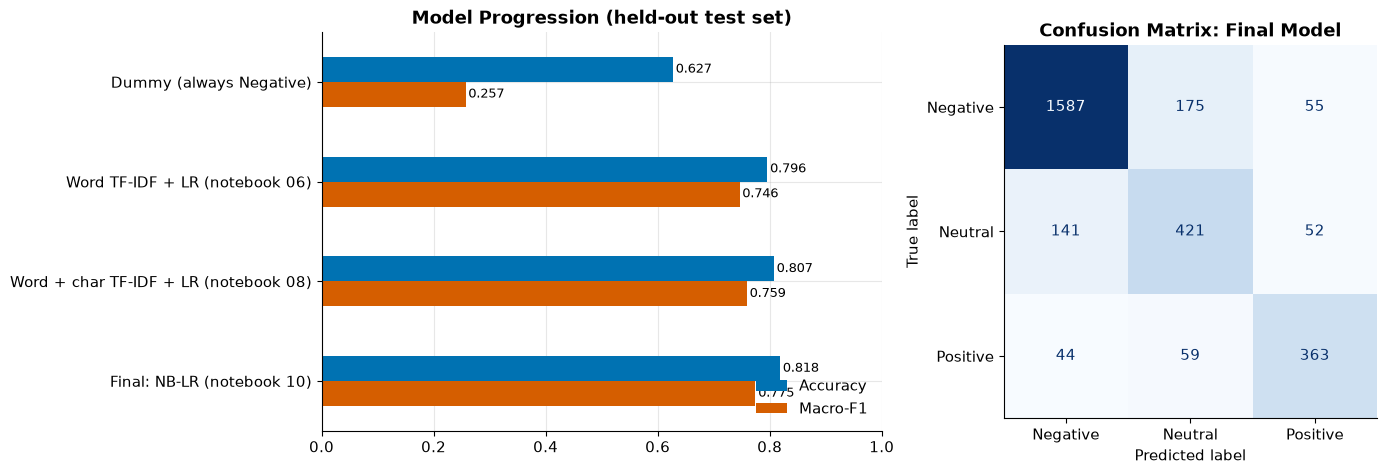

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.5, 1]})

progression[["accuracy", "macro_f1"]].plot(kind="barh", ax=axes[0], color=[PRIMARY_COLOR, SENTIMENT_COLORS["Negative"]])
axes[0].set_xlim(0, 1)
axes[0].invert_yaxis()
axes[0].set_title("Model Progression (held-out test set)")
axes[0].set_ylabel("")
axes[0].legend(["Accuracy", "Macro-F1"], loc="lower right")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=9, padding=2)

ConfusionMatrixDisplay.from_predictions(y_test, final_predictions, labels=SENTIMENT_LABELS,
                                        cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_title("Confusion Matrix: Final Model")
axes[1].grid(False)
plt.tight_layout()
save_figure("final_model_results.png")
plt.show()

In [8]:
# Per-class precision / recall / F1: notebook 08 vs final model
per_class = pd.concat({
    "notebook 08": per_class_report(y_test, reference_nb08.predict(X_test)),
    "final model": per_class_report(y_test, final_predictions),
}, axis=1)
per_class[("change", "f1")] = per_class[("final model", "f1")] - per_class[("notebook 08", "f1")]
per_class.round(4)

notebook 08                         final model                  \
           precision  recall      f1 support   precision  recall      f1   
Negative      0.8888  0.8668  0.8777    1817      0.8956  0.8734  0.8844   
Neutral       0.6295  0.6889  0.6579     614      0.6427  0.6857  0.6635   
Positive      0.7528  0.7318  0.7421     466      0.7723  0.7790  0.7756   

                  change  
         support      f1  
Negative    1817  0.0067  
Neutral      614  0.0057  
Positive     466  0.0335

**Interpretation:** the improved model is better on the held-out tweets as well as in cross-validation. Positive tweets gain the most. Neutral remains the hardest class, because the Negative ↔ Neutral boundary is where annotators themselves disagree most (notebook 07).

## 6. Stability Across Random Splits (no tuning leakage)

The notebook 08 and final model families are retrained on 10 different random 80/20 splits. For each split, `C` is **re-selected by 3-fold CV inside that split's training data** (`src.evaluation.repeated_split_evaluation`), so no split's test tweets influence the hyperparameters it is scored with. The feature design of each family is kept fixed.

In [9]:
seeds = range(10)
stability_nb08 = repeated_split_evaluation(df, build_word_char_lr, {"model__C": [0.5, 1, 2]}, seeds=seeds)
stability_final = repeated_split_evaluation(df, build_final_model, {"model__C": [4, 8, 16]}, seeds=seeds)
seed_results = pd.concat([stability_nb08.assign(model="notebook 08"), stability_final.assign(model="final model")])

display(seed_results.groupby("model")[["accuracy", "macro_f1"]].agg(["mean", "std", "min", "max"]).round(4))
display(seed_results.pivot(index="seed", columns="model", values="model__C").rename_axis(columns="selected C"))

paired = seed_results.pivot(index="seed", columns="model", values="accuracy")
wins = (paired["final model"] > paired["notebook 08"]).sum()
print(f"Final model beats notebook 08 on {wins} of {len(paired)} random splits "
      f"(mean gain {(paired['final model'] - paired['notebook 08']).mean() * 100:+.2f} accuracy points).")

accuracy                         macro_f1                        
                mean     std     min     max     mean     std     min     max
model                                                                        
final model   0.8203  0.0053  0.8101  0.8298   0.7744  0.0074  0.7603  0.7884
notebook 08   0.8081  0.0053  0.8015  0.8174   0.7624  0.0078  0.7505  0.7749

selected C,final model,notebook 08
seed,,
0,4.0,1.0
1,4.0,1.0
2,4.0,1.0
3,4.0,1.0
4,8.0,2.0
5,8.0,0.5
6,4.0,1.0
7,4.0,1.0
8,8.0,0.5


Final model beats notebook 08 on 10 of 10 random splits (mean gain +1.23 accuracy points).


**Interpretation:** the paired comparison (same split, both models, each tuned inside its own training data) is the fairest test of whether the improvement is real rather than a lucky split.

## 7. Conclusions

In [10]:
final = progression.iloc[-1]
nb08 = progression.loc["Word + char TF-IDF + LR (notebook 08)"]
final_stats = seed_results[seed_results["model"] == "final model"]
print(f"1. Selected model: {best_candidate} (5-fold CV Macro-F1 {cv_results.loc[best_candidate, 'cv_macro_f1']:.4f}).")
print(f"2. Held-out test: accuracy {final['accuracy']:.4f} (notebook 08: {nb08['accuracy']:.4f}); "
      f"Macro-F1 {final['macro_f1']:.4f} (notebook 08: {nb08['macro_f1']:.4f}); weighted-F1 {final['weighted_f1']:.4f}.")
print(f"3. Across 10 random splits (C tuned inside each split): accuracy {final_stats['accuracy'].mean():.4f} "
      f"+/- {final_stats['accuracy'].std():.4f}, macro-F1 {final_stats['macro_f1'].mean():.4f} "
      f"+/- {final_stats['macro_f1'].std():.4f}; better than notebook 08 on {wins} of 10 splits.")

1. Selected model: E. C features + NB-LR (C=4) (5-fold CV Macro-F1 0.7706).
2. Held-out test: accuracy 0.8184 (notebook 08: 0.8074); Macro-F1 0.7745 (notebook 08: 0.7592); weighted-F1 0.8201.
3. Across 10 random splits (C tuned inside each split): accuracy 0.8203 +/- 0.0053, macro-F1 0.7744 +/- 0.0074; better than notebook 08 on 10 of 10 splits.


**Takeaways**

- Careful **classical** feature engineering and a classifier designed for sentiment (NB-LR) improve accuracy by about 1.1 points on the test split (1.2 points on average across 10 re-tuned random splits, winning on all 10), with no deep learning.
- The largest gains come from features (punctuation, full vocabulary, wider character n-grams) and the classifier, not from preprocessing tricks alone.
- Label noise sets a ceiling. Notebook 07 showed that accuracy is ~88% even on tweets whose labels humans fully agreed on, and far lower on ambiguous ones. Further gains would most likely need contextual models (e.g. transformers), listed as future work.

## 8. Saving the Model and Predicting New Tweets

The notebook does not write model files. To train the final configuration on the same 80/20 split, report its test metrics and save it to `models/sentiment_model.joblib` (git-ignored), run from the repository root:

```bash
python -m src.train
python -m src.predict "@united my bag is lost and nobody answers the phone"
```